# Decentralized Hiking AI
## 01 - Real Dataset Audit

**Research Component:** Context-Aware Offline Resource Recommendation

### Objective

This notebook audits the real datasets collected for the Context-Aware Offline Resource Recommendation component.

The purpose is to:

- verify that required dataset files exist;
- inspect dataset dimensions and columns;
- identify missing values;
- validate geospatial information;
- inspect trail, terrain, weather, emergency, and connectivity-related data;
- distinguish observed data from derived features;
- identify unavailable variables before machine-learning preparation.

### Data Policy

Only real collected or legitimately derived data is used.

No synthetic or mock observations are introduced into the research dataset.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Find project root automatically
current = Path.cwd().resolve()

if current.name == "notebooks":
    PROJECT_ROOT = current.parent.parent
elif (current / "research").exists():
    PROJECT_ROOT = current
else:
    raise FileNotFoundError(
        "Could not locate project root. "
        f"Current working directory: {current}"
    )

RESEARCH_DIR = PROJECT_ROOT / "research"
DATASET_DIR = RESEARCH_DIR / "dataset"

RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"
METADATA_DIR = DATASET_DIR / "metadata"
LABELS_DIR = DATASET_DIR / "labels"

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("Exists       :", DATASET_DIR.exists())

Project root : /Users/mirshad/Desktop/Decentralized-Hiking-AI
Dataset      : /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset
Exists       : True


In [4]:
all_files = sorted([
    file for file in DATASET_DIR.rglob("*")
    if file.is_file()
])

print(f"Total files found: {len(all_files)}")
print()

for file in all_files:
    relative_path = file.relative_to(DATASET_DIR)
    size_mb = file.stat().st_size / (1024 ** 2)

    print(f"{str(relative_path):75} {size_mb:8.2f} MB")

Total files found: 164

README.md                                                                       0.01 MB
collection_report.md                                                            0.00 MB
labels/labeling_methodology.md                                                  0.00 MB
labels/resource_catalog.csv                                                     0.00 MB
metadata/connectivity_methodology.md                                            0.00 MB
metadata/copernicus_aws_readme.html                                             0.01 MB
metadata/data_dictionary.csv                                                    0.01 MB
metadata/dataset_sources.csv                                                    0.06 MB
metadata/download_log.jsonl                                                     0.03 MB
metadata/elevation_inventory.csv                                                0.00 MB
metadata/file_manifest.csv                                                      0.02 MB
metadata

In [5]:
knuckles_files = [
    file for file in all_files
    if "knuckles" in file.name.lower()
]

print(f"Knuckles-related files: {len(knuckles_files)}")
print()

for file in knuckles_files:
    print(file.relative_to(DATASET_DIR))

Knuckles-related files: 19

processed/elevation/knuckles_trail_points.csv
processed/elevation/knuckles_trail_summary.csv
processed/trails/knuckles_candidate_paths.geojson
processed/weather/knuckles_0_hourly.csv
processed/weather/knuckles_1_hourly.csv
processed/weather/knuckles_2_hourly.csv
processed/weather/knuckles_3_hourly.csv
processed/weather/knuckles_4_hourly.csv
raw/connectivity/knuckles_osm_communication_structures.geojson
raw/emergency/knuckles_facilities.geojson
raw/emergency/knuckles_facilities_osm.json
raw/trails/knuckles.overpassql
raw/trails/knuckles_hiking_relations.json
raw/trails/knuckles_pbf_extract.geojson
raw/weather/knuckles_0_2021_2025.json
raw/weather/knuckles_1_2021_2025.json
raw/weather/knuckles_2_2021_2025.json
raw/weather/knuckles_3_2021_2025.json
raw/weather/knuckles_4_2021_2025.json


In [6]:
print("PROCESSED DATA")
print("=" * 70)

for path in sorted(PROCESSED_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(DATASET_DIR))

PROCESSED DATA
processed/.DS_Store
processed/elevation/adams_peak_trail_points.csv
processed/elevation/adams_peak_trail_summary.csv
processed/elevation/ella_trail_points.csv
processed/elevation/ella_trail_summary.csv
processed/elevation/haputale_trail_points.csv
processed/elevation/haputale_trail_summary.csv
processed/elevation/horton_plains_trail_points.csv
processed/elevation/horton_plains_trail_summary.csv
processed/elevation/knuckles_trail_points.csv
processed/elevation/knuckles_trail_summary.csv
processed/elevation/meemure_trail_points.csv
processed/elevation/meemure_trail_summary.csv
processed/elevation/namunukula_trail_points.csv
processed/elevation/namunukula_trail_summary.csv
processed/elevation/riverston_trail_points.csv
processed/elevation/riverston_trail_summary.csv
processed/elevation/sigiriya_pidurangala_trail_points.csv
processed/elevation/sigiriya_pidurangala_trail_summary.csv
processed/elevation/sinharaja_trail_points.csv
processed/elevation/sinharaja_trail_summary.csv

In [7]:
trail_candidates = [
    file for file in knuckles_files
    if file.suffix.lower() in [".geojson", ".gpkg"]
    and "trail" in str(file).lower()
]

print("Possible Knuckles trail files:")

for i, file in enumerate(trail_candidates):
    print(i, file.relative_to(DATASET_DIR))

Possible Knuckles trail files:
0 processed/trails/knuckles_candidate_paths.geojson
1 raw/trails/knuckles_pbf_extract.geojson


In [8]:
processed_trails = [
    f for f in trail_candidates
    if "processed" in f.parts
]

if processed_trails:
    KNuckles_TRAIL_FILE = processed_trails[0]
elif trail_candidates:
    KNuckles_TRAIL_FILE = trail_candidates[0]
else:
    raise FileNotFoundError("No Knuckles trail GeoJSON found.")

trails = gpd.read_file(KNuckles_TRAIL_FILE)

print("Loaded:", KNuckles_TRAIL_FILE.relative_to(DATASET_DIR))
print("Rows:", len(trails))
print("Columns:", len(trails.columns))
print("CRS:", trails.crs)

Loaded: processed/trails/knuckles_candidate_paths.geojson
Rows: 559
Columns: 38
CRS: EPSG:4326


In [9]:
print("TRAIL COLUMNS")
print("=" * 50)

for column in trails.columns:
    print(column)

TRAIL COLUMNS
id
osm_type
osm_id
tags
access
bicycle
bridge
crossing
crossing:markings
cutting
description
embankment
foot
footway
highway
horse
incline
informal
lanes
layer
lit
maxspeed
motor_vehicle
motorcycle
mtb:scale
mtb:scale:uphill
name
note
sac_scale
smoothness
surface
tracktype
wheelchair
width
verified_hiking_trail
length_km
hiking_relation_ids
geometry


In [10]:
trails.head()

,id,osm_type,osm_id,tags,access,bicycle,bridge,crossing,crossing:markings,cutting,...,sac_scale,smoothness,surface,tracktype,wheelchair,width,verified_hiking_trail,length_km,hiking_relation_ids,geometry
0,way/100146710,way,100146710,"{ ""highway"": ""footway"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,1.654853,[ ],"LINESTRING (80.71194 7.41703, 80.71188 7.4173,..."
1,way/100146711,way,100146711,"{ ""highway"": ""track"", ""maxspeed"": ""25"", ""motor...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,4.966901,[ ],"LINESTRING (80.69633 7.42838, 80.6967 7.42826,..."
2,way/100146901,way,100146901,"{ ""highway"": ""path"", ""note"": ""Only for Mountai...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.859729,[ ],"LINESTRING (80.71186 7.43304, 80.71182 7.43317..."
3,way/100148512,way,100148512,"{ ""highway"": ""track"", ""maxspeed"": ""10"" }",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.995269,[ ],"LINESTRING (80.71059 7.42809, 80.71073 7.4281,..."
4,way/100149325,way,100149325,"{ ""highway"": ""footway"", ""note"": ""Only for Moun...",None,None,None,None,None,None,...,None,None,None,None,None,None,False,0.646777,[ ],"LINESTRING (80.71048 7.44174, 80.71058 7.44228..."


In [11]:
print("Geometry types:")
print(trails.geometry.geom_type.value_counts())

print()
print("Missing geometries:", trails.geometry.isna().sum())
print("Empty geometries:", trails.geometry.is_empty.sum())
print("Invalid geometries:", (~trails.geometry.is_valid).sum())

Geometry types:
LineString    559
Name: count, dtype: int64

Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0


In [12]:
missing = pd.DataFrame({
    "missing_count": trails.isna().sum(),
    "missing_percent": (trails.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    "missing_percent",
    ascending=False
)

missing

,missing_count,missing_percent
cutting,558,99.82
footway,558,99.82
sac_scale,558,99.82
mtb:scale,558,99.82
crossing,558,99.82
crossing:markings,558,99.82
lit,558,99.82
description,558,99.82
embankment,558,99.82
mtb:scale:uphill,558,99.82


In [13]:
if "highway" in trails.columns:
    print(trails["highway"].value_counts(dropna=False))
else:
    print("No 'highway' column found.")

highway
track        289
footway      125
path         124
steps         20
bridleway      1
Name: count, dtype: int64


count    559.000000
mean       0.582324
std        0.967829
min        0.005793
25%        0.099732
50%        0.243791
75%        0.644812
max        9.178720
Name: length_km, dtype: float64


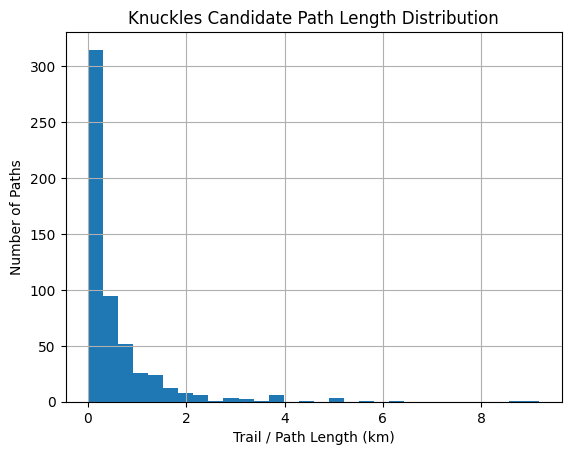

In [14]:
if "length_km" in trails.columns:
    print(trails["length_km"].describe())
    
    trails["length_km"].hist(bins=30)
    plt.xlabel("Trail / Path Length (km)")
    plt.ylabel("Number of Paths")
    plt.title("Knuckles Candidate Path Length Distribution")
    plt.show()
else:
    print("length_km is not available yet.")

## 2. Terrain and Elevation Data Audit

The terrain dataset contains real elevation information derived from the
Copernicus Digital Elevation Model (DEM).

This section verifies the trail-level and point-level elevation data before
terrain-related variables are used for feature engineering and machine-learning
model development.

The audit checks:

- availability of elevation records;
- correspondence between candidate paths and elevation summaries;
- missing elevation values;
- elevation ranges;
- elevation gain and loss;
- point-level elevation measurements;
- overall data quality.

No synthetic elevation observations are introduced.

In [15]:
elevation_summary_file = (
    PROCESSED_DIR / "elevation" / "knuckles_trail_summary.csv"
)

print("File exists:", elevation_summary_file.exists())
print("File:", elevation_summary_file)

if not elevation_summary_file.exists():
    raise FileNotFoundError(
        f"Elevation summary not found: {elevation_summary_file}"
    )

elevation_summary = pd.read_csv(elevation_summary_file)

print("\nElevation summary loaded successfully.")
print("Rows:", len(elevation_summary))
print("Columns:", len(elevation_summary.columns))

elevation_summary.head()

File exists: True
File: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed/elevation/knuckles_trail_summary.csv

Elevation summary loaded successfully.
Rows: 559
Columns: 8


,trail_id,minimum_elevation_m,maximum_elevation_m,elevation_gain_m,elevation_loss_m,profile_complete,sample_spacing_max_m,direction
0,way/100146710,1275.355835,1329.643188,137.471680,83.390137,True,60,OSM way node order
1,way/100146711,1024.330322,1281.052856,485.684814,287.749878,True,60,OSM way node order
2,way/100146901,1299.942383,1402.415527,6.243042,108.373413,True,60,OSM way node order
3,way/100148512,1332.734375,1420.415405,116.777222,29.096191,True,60,OSM way node order
4,way/100149325,1077.589600,1165.754395,0.000000,88.164795,True,60,OSM way node order


In [16]:
print("ELEVATION SUMMARY COLUMNS")
print("=" * 60)

for i, column in enumerate(elevation_summary.columns, start=1):
    print(f"{i:2}. {column}")

print("\nData types:")
print(elevation_summary.dtypes)

ELEVATION SUMMARY COLUMNS
 1. trail_id
 2. minimum_elevation_m
 3. maximum_elevation_m
 4. elevation_gain_m
 5. elevation_loss_m
 6. profile_complete
 7. sample_spacing_max_m
 8. direction

Data types:
trail_id                 object
minimum_elevation_m     float64
maximum_elevation_m     float64
elevation_gain_m        float64
elevation_loss_m        float64
profile_complete           bool
sample_spacing_max_m      int64
direction                object
dtype: object


In [17]:
elevation_missing = pd.DataFrame({
    "missing_count": elevation_summary.isna().sum(),
    "missing_percent": (
        elevation_summary.isna().mean() * 100
    ).round(2)
})

elevation_missing = elevation_missing.sort_values(
    "missing_percent",
    ascending=False
)

elevation_missing

,missing_count,missing_percent
trail_id,0,0.0
minimum_elevation_m,0,0.0
maximum_elevation_m,0,0.0
elevation_gain_m,0,0.0
elevation_loss_m,0,0.0
profile_complete,0,0.0
sample_spacing_max_m,0,0.0
direction,0,0.0


In [18]:
numeric_elevation = elevation_summary.select_dtypes(
    include=[np.number]
)

print("Numeric columns:")
print(list(numeric_elevation.columns))

numeric_elevation.describe().T

Numeric columns:
['minimum_elevation_m', 'maximum_elevation_m', 'elevation_gain_m', 'elevation_loss_m', 'sample_spacing_max_m']


,count,mean,std,min,25%,50%,75%,max
minimum_elevation_m,559.0,689.641119,288.720764,75.394760,467.032013,668.756104,918.405945,1548.818970
maximum_elevation_m,559.0,732.565804,304.927233,79.419571,483.230148,704.375732,955.168121,1856.516113
elevation_gain_m,559.0,48.562776,98.068205,0.000000,4.235947,15.550262,46.910812,1055.033112
elevation_loss_m,559.0,46.634739,94.134619,0.000000,4.286301,15.564087,49.182907,900.669601
sample_spacing_max_m,559.0,60.000000,0.000000,60.000000,60.000000,60.000000,60.000000,60.000000


Possible maximum elevation columns:
['maximum_elevation_m']


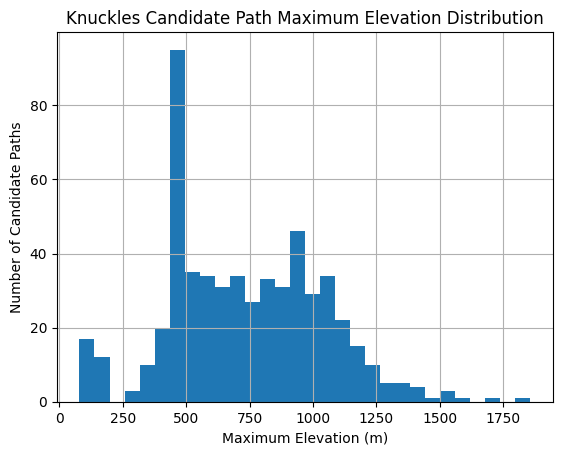

count     559.000000
mean      732.565804
std       304.927233
min        79.419571
25%       483.230148
50%       704.375732
75%       955.168121
max      1856.516113
Name: maximum_elevation_m, dtype: float64


In [19]:
possible_max_columns = [
    col for col in elevation_summary.columns
    if "max" in col.lower() and "elev" in col.lower()
]

print("Possible maximum elevation columns:")
print(possible_max_columns)

if possible_max_columns:
    max_elevation_col = possible_max_columns[0]

    elevation_summary[max_elevation_col].dropna().hist(
        bins=30
    )

    plt.xlabel("Maximum Elevation (m)")
    plt.ylabel("Number of Candidate Paths")
    plt.title(
        "Knuckles Candidate Path Maximum Elevation Distribution"
    )
    plt.show()

    print(
        elevation_summary[max_elevation_col].describe()
    )
else:
    print("No maximum elevation column detected.")

In [20]:
elevation_points_file = (
    PROCESSED_DIR / "elevation" / "knuckles_trail_points.csv"
)

print("File exists:", elevation_points_file.exists())
print("File:", elevation_points_file)

if not elevation_points_file.exists():
    raise FileNotFoundError(
        f"Elevation point file not found: {elevation_points_file}"
    )

elevation_points = pd.read_csv(elevation_points_file)

print("\nPoint-level elevation data loaded successfully.")
print("Rows:", len(elevation_points))
print("Columns:", len(elevation_points.columns))

print("\nColumns:")
for i, column in enumerate(elevation_points.columns, start=1):
    print(f"{i:2}. {column}")

elevation_points.head()

File exists: True
File: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed/elevation/knuckles_trail_points.csv

Point-level elevation data loaded successfully.
Rows: 14289
Columns: 8

Columns:
 1. region
 2. trail_id
 3. point_index
 4. latitude
 5. longitude
 6. chainage_m
 7. elevation_m
 8. slope_deg


,region,trail_id,point_index,latitude,longitude,chainage_m,elevation_m,slope_deg
0,knuckles,way/100146710,0,7.417027,80.711937,0.000000,1275.561646,18.661670
1,knuckles,way/100146710,1,7.417301,80.711875,31.120837,1279.934082,21.340280
2,knuckles,way/100146710,2,7.417574,80.711825,61.768070,1283.125610,20.355286
3,knuckles,way/100146710,3,7.417847,80.711776,92.415303,1275.355835,17.191846
4,knuckles,way/100146710,4,7.418025,80.711800,112.303188,1276.792969,13.963865


In [21]:
print("POINT-LEVEL ELEVATION QUALITY")
print("=" * 60)

print("\nDataset shape:")
print(elevation_points.shape)

print("\nMissing values:")
point_missing = pd.DataFrame({
    "missing_count": elevation_points.isna().sum(),
    "missing_percent": (
        elevation_points.isna().mean() * 100
    ).round(2)
})

display(
    point_missing.sort_values(
        "missing_percent",
        ascending=False
    )
)

print("\nNumeric statistics:")
display(
    elevation_points.select_dtypes(
        include=[np.number]
    ).describe().T
)

POINT-LEVEL ELEVATION QUALITY

Dataset shape:
(14289, 8)

Missing values:


,missing_count,missing_percent
region,0,0.0
trail_id,0,0.0
point_index,0,0.0
latitude,0,0.0
longitude,0,0.0
chainage_m,0,0.0
elevation_m,0,0.0
slope_deg,0,0.0



Numeric statistics:


,count,mean,std,min,25%,50%,75%,max
point_index,14289.0,47.664917,75.634794,0.000000,7.000000,21.000000,54.000000,581.000000
latitude,14289.0,7.392113,0.079422,7.215807,7.349492,7.385512,7.435300,7.611815
longitude,14289.0,80.769611,0.071718,80.645192,80.714361,80.762451,80.834371,80.954533
chainage_m,14289.0,1043.454091,1473.223439,0.000000,146.684640,485.992545,1263.173169,9178.719656
elevation_m,14289.0,754.597795,335.815963,75.394760,496.871216,774.570923,986.952209,1856.516113
slope_deg,14289.0,16.098519,8.311288,0.127720,9.801609,15.753878,21.595605,60.243735


## 3. Historical Weather Data Audit

Historical weather data provides environmental context for the
Context-Aware Offline Resource Recommendation component.

The dataset contains real historical weather observations collected for
multiple sampling locations within the Knuckles study region.

This section audits:

- available weather sampling files;
- temporal coverage;
- number of observations;
- weather variables;
- missing values;
- temperature;
- precipitation and rainfall;
- humidity;
- wind conditions;
- other available environmental variables.

The weather data will later be combined with trail and terrain features
to construct context-aware hiking scenarios.

No synthetic weather observations are introduced.

In [22]:
weather_dir = PROCESSED_DIR / "weather"

weather_files = sorted(
    weather_dir.glob("knuckles_*_hourly.csv")
)

print("Weather directory:", weather_dir)
print("Weather files found:", len(weather_files))
print()

for i, file in enumerate(weather_files, start=1):
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{i}. {file.name} ({size_mb:.2f} MB)")

Weather directory: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/processed/weather
Weather files found: 5

1. knuckles_0_hourly.csv (5.01 MB)
2. knuckles_1_hourly.csv (4.88 MB)
3. knuckles_2_hourly.csv (4.90 MB)
4. knuckles_3_hourly.csv (4.76 MB)
5. knuckles_4_hourly.csv (4.99 MB)


In [23]:
weather_file_summary = []

for file in weather_files:
    df = pd.read_csv(file)

    weather_file_summary.append({
        "file": file.name,
        "rows": len(df),
        "columns": len(df.columns)
    })

weather_file_summary = pd.DataFrame(weather_file_summary)

weather_file_summary

,file,rows,columns
0,knuckles_0_hourly.csv,43824,18
1,knuckles_1_hourly.csv,43824,18
2,knuckles_2_hourly.csv,43824,18
3,knuckles_3_hourly.csv,43824,18
4,knuckles_4_hourly.csv,43824,18


In [24]:
weather_frames = []

for location_id, file in enumerate(weather_files):
    df = pd.read_csv(file)

    # Preserve the sampling location
    df["weather_location_id"] = location_id
    df["source_file"] = file.name

    weather_frames.append(df)

weather = pd.concat(
    weather_frames,
    ignore_index=True
)

print("Weather datasets combined successfully.")
print()
print("Total rows:", len(weather))
print("Total columns:", len(weather.columns))
print("Sampling locations:", weather["weather_location_id"].nunique())

weather.head()

Weather datasets combined successfully.

Total rows: 219120
Total columns: 20
Sampling locations: 5


,point_id,region,requested_latitude,requested_longitude,grid_latitude,grid_longitude,api_elevation_m,timestamp,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,weather_code,cloud_cover,wind_speed_10m,wind_gusts_10m,surface_pressure,weather_location_id,source_file
0,knuckles_0,knuckles,7.45,80.8,7.400002,80.80002,1151.0,2021-01-01T00:00:00Z,17.4,18.9,91,0.0,0.0,3,100,4.0,21.2,884.8,0,knuckles_0_hourly.csv
1,knuckles_0,knuckles,7.45,80.8,7.400002,80.80002,1151.0,2021-01-01T01:00:00Z,17.6,19.1,91,0.0,0.0,3,100,3.7,20.9,885.6,0,knuckles_0_hourly.csv
2,knuckles_0,knuckles,7.45,80.8,7.400002,80.80002,1151.0,2021-01-01T02:00:00Z,18.1,19.7,89,0.1,0.1,51,100,4.7,23.4,886.6,0,knuckles_0_hourly.csv
3,knuckles_0,knuckles,7.45,80.8,7.400002,80.80002,1151.0,2021-01-01T03:00:00Z,18.1,19.5,91,0.3,0.3,51,100,7.0,27.4,887.6,0,knuckles_0_hourly.csv
4,knuckles_0,knuckles,7.45,80.8,7.400002,80.80002,1151.0,2021-01-01T04:00:00Z,19.3,20.3,85,0.2,0.2,51,100,8.8,32.8,888.2,0,knuckles_0_hourly.csv


In [25]:
print("WEATHER COLUMNS")
print("=" * 60)

for i, column in enumerate(weather.columns, start=1):
    print(f"{i:2}. {column}")

print("\nData types:")
print(weather.dtypes)

WEATHER COLUMNS
 1. point_id
 2. region
 3. requested_latitude
 4. requested_longitude
 5. grid_latitude
 6. grid_longitude
 7. api_elevation_m
 8. timestamp
 9. temperature_2m
10. apparent_temperature
11. relative_humidity_2m
12. precipitation
13. rain
14. weather_code
15. cloud_cover
16. wind_speed_10m
17. wind_gusts_10m
18. surface_pressure
19. weather_location_id
20. source_file

Data types:
point_id                 object
region                   object
requested_latitude      float64
requested_longitude     float64
grid_latitude           float64
grid_longitude          float64
api_elevation_m         float64
timestamp                object
temperature_2m          float64
apparent_temperature    float64
relative_humidity_2m      int64
precipitation           float64
rain                    float64
weather_code              int64
cloud_cover               int64
wind_speed_10m          float64
wind_gusts_10m          float64
surface_pressure        float64
weather_location_id      

In [26]:
weather_missing = pd.DataFrame({
    "missing_count": weather.isna().sum(),
    "missing_percent": (
        weather.isna().mean() * 100
    ).round(2)
})

weather_missing = weather_missing.sort_values(
    "missing_percent",
    ascending=False
)

weather_missing

,missing_count,missing_percent
point_id,0,0.0
region,0,0.0
weather_location_id,0,0.0
surface_pressure,0,0.0
wind_gusts_10m,0,0.0
wind_speed_10m,0,0.0
cloud_cover,0,0.0
weather_code,0,0.0
rain,0,0.0
precipitation,0,0.0


In [27]:
possible_time_columns = [
    col for col in weather.columns
    if any(
        keyword in col.lower()
        for keyword in ["time", "date", "timestamp"]
    )
]

print("Possible time columns:")
print(possible_time_columns)

Possible time columns:
['timestamp']


In [28]:
if possible_time_columns:
    time_col = possible_time_columns[0]

    weather[time_col] = pd.to_datetime(
        weather[time_col],
        errors="coerce"
    )

    print("Time column:", time_col)
    print("Earliest observation:", weather[time_col].min())
    print("Latest observation:  ", weather[time_col].max())
    print(
        "Invalid timestamps:",
        weather[time_col].isna().sum()
    )
else:
    print("No time column detected.")

Time column: timestamp
Earliest observation: 2021-01-01 00:00:00+00:00
Latest observation:   2025-12-31 23:00:00+00:00
Invalid timestamps: 0


In [29]:
weather_numeric = weather.select_dtypes(
    include=[np.number]
)

print("Numeric weather columns:")
print(list(weather_numeric.columns))

weather_numeric.describe().T

Numeric weather columns:
['requested_latitude', 'requested_longitude', 'grid_latitude', 'grid_longitude', 'api_elevation_m', 'temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'precipitation', 'rain', 'weather_code', 'cloud_cover', 'wind_speed_10m', 'wind_gusts_10m', 'surface_pressure', 'weather_location_id']


,count,mean,std,min,25%,50%,75%,max
requested_latitude,219120.0,7.430000,0.112250,7.300000,7.300000,7.450000,7.550000,7.550000
requested_longitude,219120.0,80.800000,0.089443,80.700000,80.700000,80.800000,80.900000,80.900000
grid_latitude,219120.0,7.420001,0.116618,7.300003,7.300003,7.400002,7.500000,7.599998
grid_longitude,219120.0,80.800006,0.089436,80.700010,80.700010,80.800020,80.899994,80.899994
api_elevation_m,219120.0,710.800000,366.668752,142.000000,464.000000,790.000000,1007.000000,1151.000000
temperature_2m,219120.0,23.162950,3.438551,11.900000,20.500000,22.800000,25.400000,37.900000
apparent_temperature,219120.0,25.918194,4.231824,10.400000,22.600000,25.400000,28.800000,43.900000
relative_humidity_2m,219120.0,80.513363,13.678115,29.000000,72.000000,83.000000,92.000000,100.000000
precipitation,219120.0,0.213162,0.849492,0.000000,0.000000,0.000000,0.100000,26.300000
rain,219120.0,0.213162,0.849492,0.000000,0.000000,0.000000,0.100000,26.300000


Possible temperature columns:
['temperature_2m']


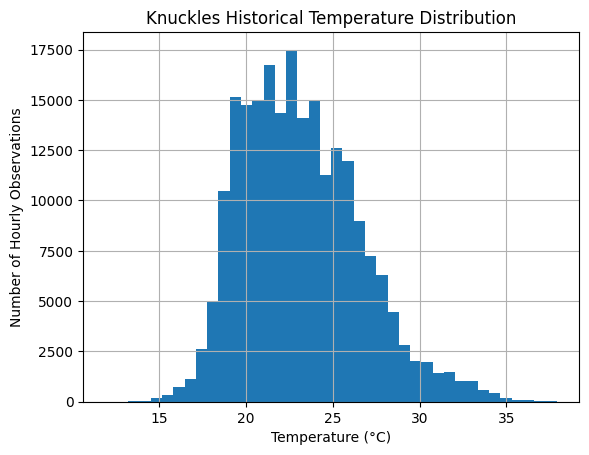

count    219120.000000
mean         23.162950
std           3.438551
min          11.900000
25%          20.500000
50%          22.800000
75%          25.400000
max          37.900000
Name: temperature_2m, dtype: float64


In [30]:
temperature_columns = [
    col for col in weather.columns
    if "temperature" in col.lower()
    and "apparent" not in col.lower()
]

print("Possible temperature columns:")
print(temperature_columns)

if temperature_columns:
    temperature_col = temperature_columns[0]

    weather[temperature_col].dropna().hist(
        bins=40
    )

    plt.xlabel("Temperature (°C)")
    plt.ylabel("Number of Hourly Observations")
    plt.title(
        "Knuckles Historical Temperature Distribution"
    )
    plt.show()

    print(
        weather[temperature_col].describe()
    )

In [31]:
rain_columns = [
    col for col in weather.columns
    if "rain" in col.lower()
    or "precipitation" in col.lower()
]

print("Rain / precipitation columns:")
print(rain_columns)

for col in rain_columns:
    if pd.api.types.is_numeric_dtype(weather[col]):
        print(f"\n{col}")
        print(weather[col].describe())

Rain / precipitation columns:
['precipitation', 'rain']

precipitation
count    219120.000000
mean          0.213162
std           0.849492
min           0.000000
25%           0.000000
50%           0.000000
75%           0.100000
max          26.300000
Name: precipitation, dtype: float64

rain
count    219120.000000
mean          0.213162
std           0.849492
min           0.000000
25%           0.000000
50%           0.000000
75%           0.100000
max          26.300000
Name: rain, dtype: float64


In [32]:
if possible_time_columns:
    time_col = possible_time_columns[0]

    weather["year"] = weather[time_col].dt.year

    yearly_counts = (
        weather["year"]
        .value_counts()
        .sort_index()
    )

    print("Hourly observations by year:")
    print(yearly_counts)

Hourly observations by year:
year
2021    43800
2022    43800
2023    43800
2024    43920
2025    43800
Name: count, dtype: int64


## 4. Emergency and Support Facility Data Audit

Access to emergency and support facilities is important when preparing
offline resources for hikers.

This section audits real OpenStreetMap-derived facilities around the
Knuckles study region.

These facilities may later be used to derive contextual variables such as:

- distance to the nearest hospital;
- distance to the nearest clinic;
- distance to the nearest police station;
- distance to other emergency/support facilities;
- remoteness indicators.

The raw facility locations themselves are not automatically treated as
risk labels. They are contextual geographic information.

In [33]:
emergency_file = (
    RAW_DIR / "emergency" / "knuckles_facilities.geojson"
)

print("File exists:", emergency_file.exists())
print("File:", emergency_file)

if not emergency_file.exists():
    raise FileNotFoundError(
        f"Emergency facility file not found: {emergency_file}"
    )

emergency = gpd.read_file(emergency_file)

print("\nEmergency/support data loaded.")
print("Rows:", len(emergency))
print("Columns:", len(emergency.columns))
print("CRS:", emergency.crs)

emergency.head()

File exists: True
File: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/raw/emergency/knuckles_facilities.geojson

Emergency/support data loaded.
Rows: 51
Columns: 28
CRS: EPSG:4326


,id,osm_type,osm_id,tags,addr:city,addr:housename,addr:postcode,addr:street,amenity,building,...,natural,opening_hours,operator,operator:type,phone,reservation,shelter_type,tourism,wheelchair,geometry
0,node/2308038415,node,2308038415,"{ ""amenity"": ""police"", ""name"": ""Ududumbara"" }",None,None,None,None,police,None,...,None,None,None,None,None,None,None,None,None,POINT (80.87936 7.3179)
1,node/2315533313,node,2315533313,"{ ""amenity"": ""hospital"", ""name"": ""Medamahanuwa...",None,None,None,None,hospital,None,...,None,None,None,None,None,None,None,None,None,POINT (80.81517 7.28975)
2,node/2334181663,node,2334181663,"{ ""amenity"": ""police"", ""name"": ""Divisional Cri...",None,None,None,None,police,None,...,None,None,None,None,None,None,None,None,None,POINT (80.76392 7.31014)
3,node/2334181719,node,2334181719,"{ ""amenity"": ""hospital"", ""name"": ""Teldeniya Di...",None,None,None,None,hospital,None,...,None,None,None,None,None,None,None,None,None,POINT (80.76444 7.30774)
4,node/2335114652,node,2335114652,"{ ""amenity"": ""hospital"", ""name"": ""Digana"" }",None,None,None,None,hospital,None,...,None,None,None,None,None,None,None,None,None,POINT (80.73484 7.29428)


In [34]:
print("EMERGENCY / SUPPORT COLUMNS")
print("=" * 60)

for i, column in enumerate(emergency.columns, start=1):
    print(f"{i:2}. {column}")

print("\nGeometry types:")
print(emergency.geometry.geom_type.value_counts())

EMERGENCY / SUPPORT COLUMNS
 1. id
 2. osm_type
 3. osm_id
 4. tags
 5. addr:city
 6. addr:housename
 7. addr:postcode
 8. addr:street
 9. amenity
10. building
11. drinking_water
12. emergency
13. fireplace
14. healthcare
15. healthcare:speciality
16. intermittent
17. name
18. name:en
19. natural
20. opening_hours
21. operator
22. operator:type
23. phone
24. reservation
25. shelter_type
26. tourism
27. wheelchair
28. geometry

Geometry types:
Point         44
LineString     7
Name: count, dtype: int64


In [35]:
emergency_missing = pd.DataFrame({
    "missing_count": emergency.isna().sum(),
    "missing_percent": (
        emergency.isna().mean() * 100
    ).round(2)
})

emergency_missing = emergency_missing.sort_values(
    "missing_percent",
    ascending=False
)

emergency_missing

,missing_count,missing_percent
phone,50,98.04
shelter_type,50,98.04
wheelchair,50,98.04
operator:type,50,98.04
operator,50,98.04
addr:housename,50,98.04
addr:postcode,50,98.04
opening_hours,50,98.04
natural,50,98.04
intermittent,50,98.04


In [36]:
candidate_category_columns = [
    col for col in emergency.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "amenity",
            "healthcare",
            "emergency",
            "type",
            "category"
        ]
    )
]

print("Possible facility category columns:")
print(candidate_category_columns)

for col in candidate_category_columns:
    print(f"\n--- {col} ---")

    print(
        emergency[col]
        .value_counts(dropna=False)
        .head(30)
    )

Possible facility category columns:
['osm_type', 'amenity', 'emergency', 'healthcare', 'healthcare:speciality', 'operator:type', 'shelter_type']

--- osm_type ---
osm_type
node    44
way      7
Name: count, dtype: int64

--- amenity ---
amenity
hospital          24
police            12
shelter            4
doctors            4
clinic             3
drinking_water     2
None               1
ranger_station     1
Name: count, dtype: int64

--- emergency ---
emergency
None    48
yes      2
no       1
Name: count, dtype: int64

--- healthcare ---
healthcare
None           43
hospital        6
alternative     1
clinic          1
Name: count, dtype: int64

--- healthcare:speciality ---
healthcare:speciality
None        49
ayurveda     1
general      1
Name: count, dtype: int64

--- operator:type ---
operator:type
None       50
private     1
Name: count, dtype: int64

--- shelter_type ---
shelter_type
None               50
weather_shelter     1
Name: count, dtype: int64


## 5. Connectivity-Related Data Audit

The available connectivity-related dataset contains OpenStreetMap-mapped
communication infrastructure within the Knuckles study region.

This dataset is treated as a **connectivity proxy**, not as direct
measurement of cellular signal strength or network availability.

Communication infrastructure may provide contextual information about
relative remoteness or potential connectivity, but it cannot independently
establish whether a hiker has usable mobile coverage at a particular point.

Therefore, any connectivity-related feature derived from this dataset will
be clearly identified as a proxy unless validated against direct coverage
or signal measurements.

In [37]:
connectivity_file = (
    RAW_DIR
    / "connectivity"
    / "knuckles_osm_communication_structures.geojson"
)

print("File exists:", connectivity_file.exists())
print("File:", connectivity_file)

if not connectivity_file.exists():
    raise FileNotFoundError(
        f"Connectivity file not found: {connectivity_file}"
    )

connectivity = gpd.read_file(connectivity_file)

print("\nConnectivity proxy data loaded.")
print("Rows:", len(connectivity))
print("Columns:", len(connectivity.columns))
print("CRS:", connectivity.crs)

connectivity.head()

File exists: True
File: /Users/mirshad/Desktop/Decentralized-Hiking-AI/research/dataset/raw/connectivity/knuckles_osm_communication_structures.geojson

Connectivity proxy data loaded.
Rows: 12
Columns: 8
CRS: EPSG:4326


,id,osm_id,osm_type,tags,source,coverage_known,osm_mobile_phone_tag_present,geometry
0,node/3740820499,3740820499,node,"{ ""man_made"": ""tower"", ""name"": ""Telecommunicat...",OSM via Geofabrik 2026-10-12,False,False,POINT (80.69142 7.38838)
1,node/3740820678,3740820678,node,"{ ""man_made"": ""tower"", ""name"": ""Telecommunicat...",OSM via Geofabrik 2026-10-12,False,False,POINT (80.69071 7.38827)
2,node/4934155304,4934155304,node,"{ ""height"": ""50"", ""man_made"": ""tower"", ""techno...",OSM via Geofabrik 2026-10-12,False,False,POINT (80.73351 7.302)
3,node/5476458014,5476458014,node,"{ ""height"": ""100"", ""man_made"": ""tower"", ""name""...",OSM via Geofabrik 2026-10-12,False,False,POINT (80.7353 7.30063)
4,node/5476458557,5476458557,node,"{ ""height"": ""75"", ""man_made"": ""tower"", ""name"":...",OSM via Geofabrik 2026-10-12,False,False,POINT (80.72615 7.31073)


In [38]:
print("CONNECTIVITY DATA COLUMNS")
print("=" * 60)

for i, column in enumerate(connectivity.columns, start=1):
    print(f"{i:2}. {column}")

print("\nGeometry types:")
print(connectivity.geometry.geom_type.value_counts())

print("\nMissing geometries:")
print(connectivity.geometry.isna().sum())

print("\nEmpty geometries:")
print(connectivity.geometry.is_empty.sum())

print("\nInvalid geometries:")
print((~connectivity.geometry.is_valid).sum())

CONNECTIVITY DATA COLUMNS
 1. id
 2. osm_id
 3. osm_type
 4. tags
 5. source
 6. coverage_known
 7. osm_mobile_phone_tag_present
 8. geometry

Geometry types:
Point    12
Name: count, dtype: int64

Missing geometries:
0

Empty geometries:
0

Invalid geometries:
0


In [39]:
connectivity_missing = pd.DataFrame({
    "missing_count": connectivity.isna().sum(),
    "missing_percent": (
        connectivity.isna().mean() * 100
    ).round(2)
})

connectivity_missing = connectivity_missing.sort_values(
    "missing_percent",
    ascending=False
)

connectivity_missing

,missing_count,missing_percent
id,0,0.0
osm_id,0,0.0
osm_type,0,0.0
tags,0,0.0
source,0,0.0
coverage_known,0,0.0
osm_mobile_phone_tag_present,0,0.0
geometry,0,0.0


In [40]:
connectivity_category_columns = [
    col for col in connectivity.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "tower",
            "communication",
            "man_made",
            "type",
            "telecom",
            "mobile"
        ]
    )
]

print("Possible connectivity category columns:")
print(connectivity_category_columns)

for col in connectivity_category_columns:
    print(f"\n--- {col} ---")
    
    print(
        connectivity[col]
        .value_counts(dropna=False)
        .head(30)
    )

Possible connectivity category columns:
['osm_type', 'osm_mobile_phone_tag_present']

--- osm_type ---
osm_type
node    12
Name: count, dtype: int64

--- osm_mobile_phone_tag_present ---
osm_mobile_phone_tag_present
False    12
Name: count, dtype: int64


In [41]:
if "tags" in connectivity.columns:
    print("Example connectivity tags:")
    
    for i, value in enumerate(
        connectivity["tags"].head(20),
        start=1
    ):
        print(f"{i:2}. {value}")
else:
    print("No 'tags' column found.")

Example connectivity tags:
 1. { "man_made": "tower", "name": "Telecommunication Tower", "tower:type": "communication" }
 2. { "man_made": "tower", "name": "Telecommunication Tower", "tower:type": "communication" }
 3. { "height": "50", "man_made": "tower", "technology": "GSM 900", "tower:type": "communication" }
 4. { "height": "100", "man_made": "tower", "name": "Telecom Tower", "tower:type": "communication" }
 5. { "height": "75", "man_made": "tower", "name": "Telecom Tower", "tower:type": "communication" }
 6. { "height": "100", "man_made": "tower", "name": "Telecom Tower", "tower:type": "communication" }
 7. { "height": "100", "man_made": "tower", "name": "Telecom Tower", "tower:type": "communication" }
 8. { "height": "100", "man_made": "tower", "name": "Telecom Tower", "tower:type": "communication" }
 9. { "height": "150", "man_made": "mast", "name": "Telecom Tower", "tower:construction": "lattice", "tower:type": "communication" }
10. { "height": "40", "man_made": "tower", "towe